In [78]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
import seaborn as sns

In [79]:
df = pd.read_csv('bank-additional-full-1.csv', sep=';')

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41199 entries, 0 to 41198
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41195 non-null  float64
 1   job             41194 non-null  str    
 2   marital         41194 non-null  str    
 3   education       41194 non-null  str    
 4   default         41195 non-null  str    
 5   housing         41196 non-null  str    
 6   loan            41195 non-null  str    
 7   contact         41195 non-null  str    
 8   month           41196 non-null  str    
 9   day_of_week     41196 non-null  str    
 10  duration        41196 non-null  float64
 11  campaign        41196 non-null  float64
 12  pdays           41196 non-null  float64
 13  previous        41196 non-null  float64
 14  poutcome        41194 non-null  str    
 15  emp.var.rate    41196 non-null  float64
 16  cons.price.idx  41195 non-null  float64
 17  cons.conf.idx   41196 non-null  float64
 1

In [81]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [82]:
# p_days = previous contact days for campaign
# poutcome = outcome of the previous marketing campaign
# emp.var.rate = employment variation rate --- quarterly indicator
# cons.price.idx = consumer price index ----- monthly indicator
# cons.conf.idx = consumer confidence index ----- monthly indicator
# cons.price.idx = consumer price index ----- monthly indicator
# euribor3m = euribor 3 month rate ----- daily indicator
# nr.employed = number of employees ----- quarterly indicator
# y target -> whether the client has subscribed a term deposit or not


## EDA

In [83]:
df.duplicated().sum()
#Drop duplicates
df.drop_duplicates(inplace=True)

In [84]:
df.isnull().sum()

age               2
job               3
marital           3
education         3
default           2
housing           1
loan              2
contact           2
month             1
day_of_week       1
duration          1
campaign          1
pdays             1
previous          1
poutcome          3
emp.var.rate      1
cons.price.idx    2
cons.conf.idx     1
euribor3m         1
nr.employed       1
y                 1
dtype: int64

In [85]:
df.isnull().sum().sum() 
# Fill object null with mode and int/float with mean
for i in df.columns:
    if(df[i].dtype=='str'):
        df[i]=df[i].fillna(df[i].mode()[0])
    elif(df[i].dtype=='int64' or df[i].dtype=='float64'):
        df[i]=df[i].fillna(df[i].mean())

10


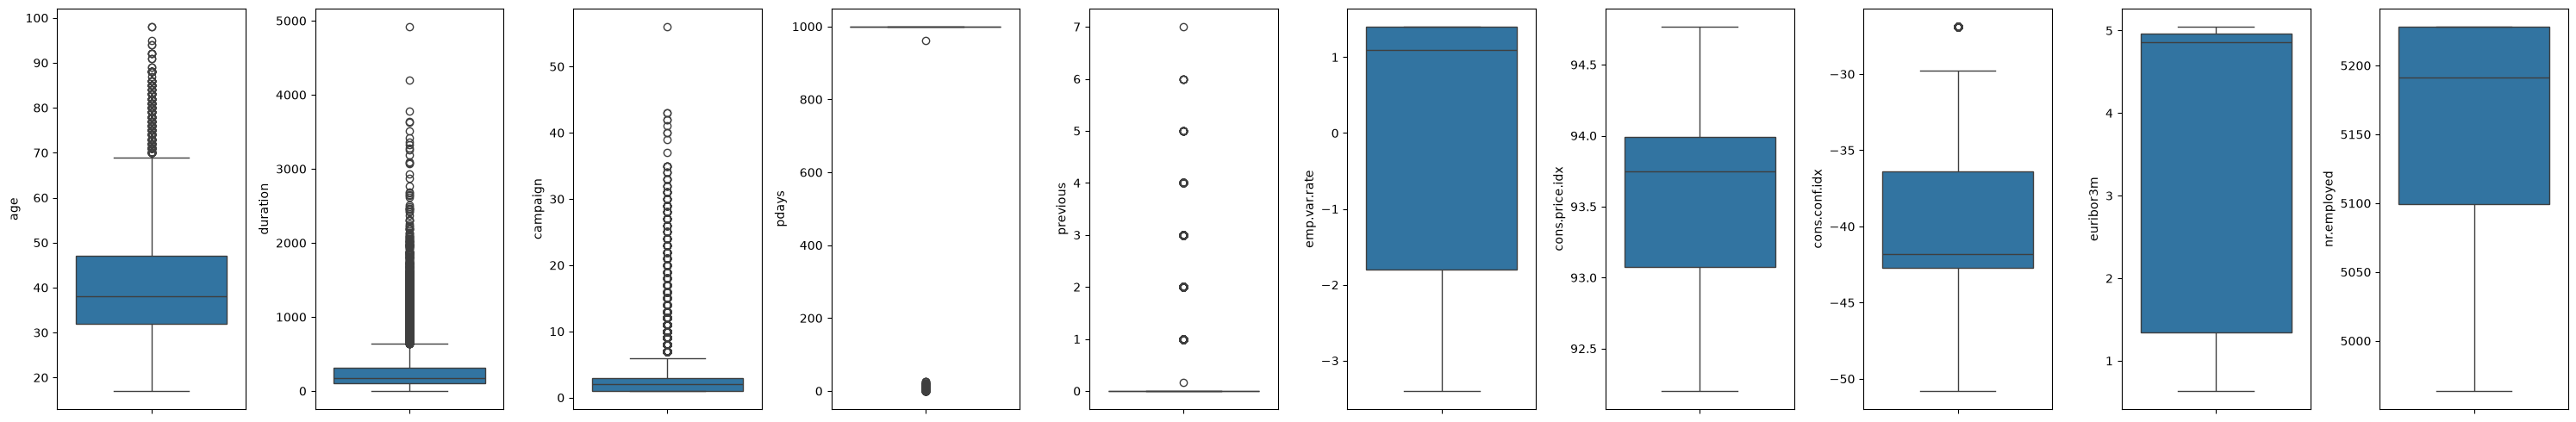

In [86]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
print(len(numeric_columns))
fig, axes = plt.subplots(1, len(numeric_columns), figsize=(30, 5))
for ax, col in zip(axes, numeric_columns):
    #df.boxplot(column=col, ax=ax) 
    sns.boxplot(y=col, data=df, ax=ax)

plt.tight_layout()
plt.show()

In [87]:
## 
Outliers =['duration', 'campaign', 'cons.conf.idx']

df.shape

(41184, 21)

In [93]:
for i in Outliers:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    print(f'IQR {i}: {IQR:.2f}')
    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR
    df = df[(df[i] >= lower_bound) & (df[i] <= upper_bound)]

IQR duration: 167.00
IQR campaign: 2.00
IQR cons.conf.idx: 6.30


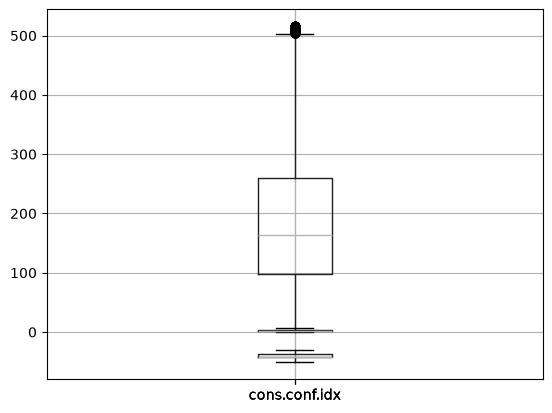

In [94]:
for i in Outliers:
    df.boxplot(column=i)


In [95]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [96]:
df.info()

<class 'pandas.DataFrame'>
Index: 33961 entries, 0 to 41198
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             33961 non-null  float64
 1   job             33961 non-null  str    
 2   marital         33961 non-null  str    
 3   education       33961 non-null  str    
 4   default         33961 non-null  str    
 5   housing         33961 non-null  str    
 6   loan            33961 non-null  str    
 7   contact         33961 non-null  str    
 8   month           33961 non-null  str    
 9   day_of_week     33961 non-null  str    
 10  duration        33961 non-null  float64
 11  campaign        33961 non-null  float64
 12  pdays           33961 non-null  float64
 13  previous        33961 non-null  float64
 14  poutcome        33961 non-null  str    
 15  emp.var.rate    33961 non-null  float64
 16  cons.price.idx  33961 non-null  float64
 17  cons.conf.idx   33961 non-null  float64
 18  eu

In [97]:
for i in df.columns:
    if(df[i].dtype =='str'):
        df[i]=le.fit_transform(df[i])

In [98]:
df.info()

<class 'pandas.DataFrame'>
Index: 33961 entries, 0 to 41198
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             33961 non-null  float64
 1   job             33961 non-null  int64  
 2   marital         33961 non-null  int64  
 3   education       33961 non-null  int64  
 4   default         33961 non-null  int64  
 5   housing         33961 non-null  int64  
 6   loan            33961 non-null  int64  
 7   contact         33961 non-null  int64  
 8   month           33961 non-null  int64  
 9   day_of_week     33961 non-null  int64  
 10  duration        33961 non-null  float64
 11  campaign        33961 non-null  float64
 12  pdays           33961 non-null  float64
 13  previous        33961 non-null  float64
 14  poutcome        33961 non-null  int64  
 15  emp.var.rate    33961 non-null  float64
 16  cons.price.idx  33961 non-null  float64
 17  cons.conf.idx   33961 non-null  float64
 18  eu

In [99]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,3,1,0,0,0,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0,0
1,57.0,7,1,3,1,0,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0,0
2,37.0,7,1,3,0,2,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0,0
3,40.0,0,1,1,0,0,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0,0
4,56.0,7,1,3,0,0,2,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41192,74.0,5,1,5,0,2,0,0,7,0,...,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6,0
41193,94.0,5,1,5,0,2,0,0,7,0,...,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6,0
41195,74.0,0,1,5,0,2,0,0,7,0,...,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6,0
41196,74.0,5,1,6,0,2,0,0,7,0,...,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6,0


In [ ]:
df.y.value_counts() # there is a class imbalance in the target variable. We will use SMOTE to balance the classes.


y
0    31536
1     2425
Name: count, dtype: int64

In [101]:
X = df.drop('y', axis=1)
y = df['y']

In [106]:
display(X)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56.0,3,1,0,0,0,0,1,6,1,261.0,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0
1,57.0,7,1,3,1,0,0,1,6,1,149.0,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0
2,37.0,7,1,3,0,2,0,1,6,1,226.0,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0
3,40.0,0,1,1,0,0,0,1,6,1,151.0,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0
4,56.0,7,1,3,0,0,2,1,6,1,307.0,1.0,999.0,0.0,1,1.1,93.994000,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41192,74.0,5,1,5,0,2,0,0,7,0,239.0,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6
41193,94.0,5,1,5,0,2,0,0,7,0,239.0,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6
41195,74.0,0,1,5,0,2,0,0,7,0,239.0,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6
41196,74.0,5,1,6,0,2,0,0,7,0,239.0,3.0,999.0,1.0,0,-1.1,94.767000,-50.8,1.028,4963.6


In [107]:
display(y)


0        0
1        0
2        0
3        0
4        0
        ..
41192    0
41193    0
41195    0
41196    0
41198    0
Name: y, Length: 33961, dtype: int64

In [121]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [122]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(27168, 20) (6793, 20) (27168,) (6793,)


In [123]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [124]:
# logistic regression model
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=100)
lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [ ]:
from sklearn.preprocessing import StandardScaler

y_pred = lr.predict(X_test)



Accuracy: 0.95%


In [129]:
from sklearn.metrics import accuracy_score
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

Accuracy: 0.95


In [143]:
from sklearn.metrics import *

confusion_matrix(y_test, y_pred)
# (tn, fp,
# fn, tp)

array([[6225,  101],
       [ 263,  204]])

In [144]:
print(f"Accuracy: {(6225 + 204)/(263 + 101 + 6225 + 204)}")

Accuracy: 0.9464154276461063


In [145]:
print(f'precision_score: {precision_score(y_test, y_pred):.2f}')
# precision = tp / (tp + fp)
print(f"Precision: {204 / (204 + 101):.2f}")

precision_score: 0.67
Precision: 0.67


In [146]:
# Class Imbalance 

y_test.value_counts()

y
0    6326
1     467
Name: count, dtype: int64

In [ ]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.96      0.98      0.97      6326
           1       0.67      0.44      0.53       467

    accuracy                           0.95      6793
   macro avg       0.81      0.71      0.75      6793
weighted avg       0.94      0.95      0.94      6793



In [155]:
# Test the columns of X_input
len(X.columns)

20

In [158]:
# Generate a random X_input of this classifier to predict the output
X_input = np.random.rand(1, 20)  
y_pred_input = lr.predict(X_input)
print(y_pred_input)

[0]
